In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

RANDOM_STATE = 1

In [2]:
df = pd.read_csv('cleaned_sfr_2025H2.csv', low_memory=False)
df = df.dropna(axis=1, how='all')
print(df.shape)

(65956, 46)


In [15]:
ratio = df['ClosePrice'] / df['ListPrice']
lo, hi = df['ClosePrice'].quantile([0.005, 0.995])
mask = ratio.between(0.5, 2) & df['ClosePrice'].between(lo, hi)
data = df[mask].copy()

## 2. Features

I only included numerical variables to start out with

In [14]:
features = [
    'LivingArea', 'LotSizeSquareFeet', 'BedroomsTotal', 'BathroomsTotalInteger',
    'YearBuilt', 'Stories', 'GarageSpaces', 'ParkingTotal',
    'Latitude', 'Longitude',
    'ViewYN', 'WaterfrontYN', 'BasementYN', 'PoolPrivateYN',
    'AttachedGarageYN', 'FireplaceYN', 'NewConstructionYN',
]
target = 'ClosePrice'

X = data[features]
y = data[target]


## 3. Train/test split and imputation

80/20 split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (52216, 17)  Test: (13055, 17)


## 4. Model Training

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

## 5. Evaluate

In [12]:
def report(y_true, y_pred):
    return {
        'R2': r2_score(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
    }

results = pd.DataFrame({'Train': report(y_train, pred_train),'Test': report(y_test, pred_test)}).T
print(results)

             R2            MAE           RMSE
Train  0.431751  446742.405317  702966.748628
Test   0.433530  452784.186149  716620.086051


In [13]:
coefs = pd.Series(model.coef_, index=features).sort_values()
print(coefs)

YearBuilt               -9748.911725
Longitude                -135.363298
GarageSpaces              -71.897349
AttachedGarageYN          -70.651795
ParkingTotal              -63.558674
BathroomsTotalInteger     -34.043082
Stories                   -29.850909
NewConstructionYN         -22.996660
ViewYN                    -18.004265
BedroomsTotal              -9.960758
WaterfrontYN               -0.017363
LotSizeSquareFeet          -0.000036
PoolPrivateYN               2.067464
BasementYN                 10.710647
FireplaceYN                16.515103
Latitude                   32.272059
LivingArea                706.348773
dtype: float64


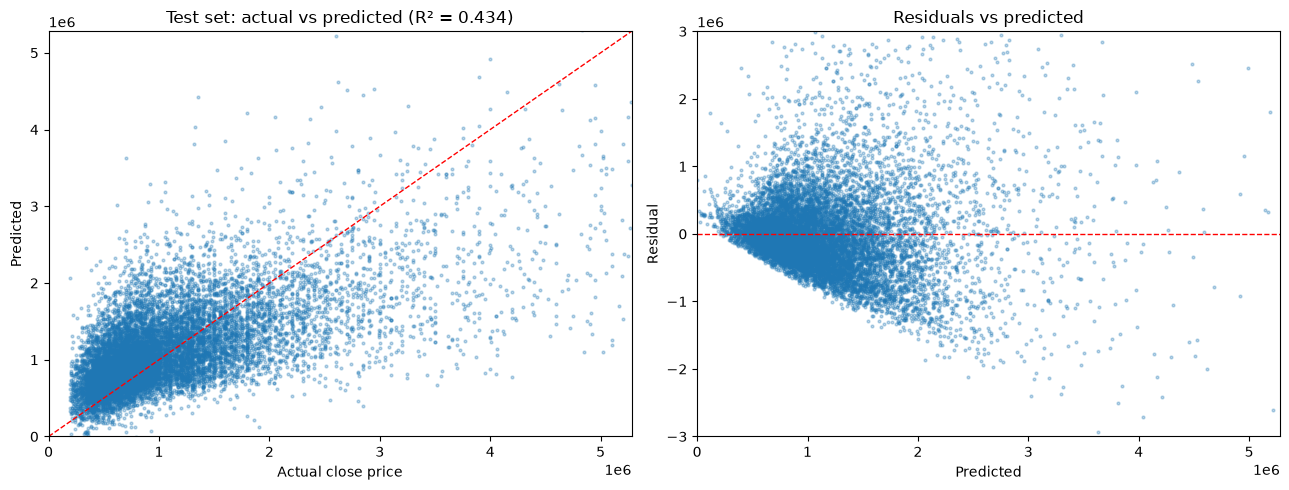

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, pred_test, s=4, alpha=0.3)
lim = [0, y_test.quantile(0.99)]
axes[0].plot(lim, lim, 'r--', lw=1)
axes[0].set(xlim=lim, ylim=lim, xlabel='Actual close price', ylabel='Predicted',
            title=f'Test set: actual vs predicted (R² = {results.loc["Test","R2"]:.3f})')

resid = y_test - pred_test
axes[1].scatter(pred_test, resid, s=4, alpha=0.3)
axes[1].axhline(0, color='r', ls='--', lw=1)
axes[1].set(xlim=lim, ylim=(-3e6, 3e6), xlabel='Predicted', ylabel='Residual',
            title='Residuals vs predicted')
plt.tight_layout(); plt.show()

## 6. BaseLine Results

In [10]:
baseline = {
    'model': 'LinearRegression (raw ClosePrice, 17 numeric/binary features)',
    'n_train': len(X_train), 'n_test': len(X_test),
    'test_R2': float(round(results.loc['Test', 'R2'], 4)),
    'test_MAE': int(round(results.loc['Test', 'MAE'])),
    'test_RMSE': int(round(results.loc['Test', 'RMSE'])),
    'random_state': RANDOM_STATE,
}
pd.DataFrame([baseline]).to_csv('baseline_results.csv', index=False)
baseline

{'model': 'LinearRegression (raw ClosePrice, 17 numeric/binary features)',
 'n_train': 52216,
 'n_test': 13055,
 'test_R2': 0.4335,
 'test_MAE': 452784,
 'test_RMSE': 716620,
 'random_state': 1}